# SVM (TF-IDF + LinearSVC)

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, auc, classification_report, confusion_matrix, roc_curve
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

DATASET_PATH = "D:\\NLP\\data\\merged_dataset(1).txt"


### Nạp dữ liệu và chia theo chủ đề

In [3]:
df = pd.read_csv(DATASET_PATH)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.dropna(subset=["text"], inplace=True)
df["text"] = df["text"].astype(str)

train_sources = [
    "HC3_reddit_eli5",
    "HC3_finance",
    "DAIGT_v2_Distance learning",
    "DAIGT_v2_Seeking multiple opinions",
    "HC3_open_qa",
]
val_sources = [
    "DAIGT_v2_Car-free cities",
    "DAIGT_v2_Does the electoral college work?",
    "DAIGT_v2_Facial action coding system",
    "DAIGT_v2_Mandatory extracurricular activities",
    "DAIGT_v2_Summer projects",
    "HC3_medicine",
    "DAIGT_v2_Driverless cars",
    "DAIGT_v2_Exploring Venus",
]
test_sources = [
    "DAIGT_v2_Cell phones at school",
    "DAIGT_v2_Grades for extracurricular activities",
    "DAIGT_v2_Community service",
    'DAIGT_v2_"A Cowboy Who Rode the Waves"',
    "DAIGT_v2_The Face on Mars",
    "HC3_wiki_csai",
    "DAIGT_v2_Phones and driving",
]

missing = set(train_sources + val_sources + test_sources) - set(df["source"].unique())
assert not missing, f"Không tìm thấy các nguồn: {missing}"

train_df = df[df["source"].isin(train_sources)]
val_df = df[df["source"].isin(val_sources)]
test_df = df[df["source"].isin(test_sources)]

X_train, y_train = train_df["text"].values, train_df["label"].values
X_val, y_val = val_df["text"].values, val_df["label"].values
X_test, y_test = test_df["text"].values, test_df["label"].values

print(f"Tổng số mẫu:  {len(df)}")
print(f"Tập train:    {len(X_train)} ({len(X_train) / len(df):.1%})")
print(f"Tập val:      {len(X_val)} ({len(X_val) / len(df):.1%})")
print(f"Tập test:     {len(X_test)} ({len(X_test) / len(df):.1%})")

Tổng số mẫu:  124195
Tập train:    85897 (69.2%)
Tập val:      24987 (20.1%)
Tập test:     13311 (10.7%)


### Pipeline và lưới siêu tham số

In [4]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2))),
    ("clf", LinearSVC(dual=False, max_iter=2000, random_state=42)),
])

param_grid = {
    "tfidf__max_features": [15000, 25000, 35000],
    "clf__C": [0.1, 1, 10],
    "clf__penalty": ["l1", "l2"],
}

### GridSearchCV (5-fold)

In [6]:
X_train_fit = [str(x) for x in X_train]
y_train_fit = np.asarray(y_train, dtype=int)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy",
    verbose=2,
    n_jobs=1, 
)

start_time = time.time()
grid_search.fit(X_train_fit, y_train_fit)
grid_time = time.time() - start_time
print(f"\nGridSearchCV hoàn thành sau {grid_time:.2f} giây.")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=15000; total time=  43.8s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=15000; total time=  56.5s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=15000; total time=  43.8s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=15000; total time=  42.5s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=15000; total time=  30.0s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=25000; total time=  29.1s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=25000; total time=  29.2s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=25000; total time=  29.7s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=25000; total time=  30.8s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=25000; total time=  45.6s
[CV] END clf__C=0.1, clf__penalty=l1, tfidf__max_features=35000; total time=  44.8s
[CV] END clf__C

### Kết quả tìm kiếm siêu tham số

In [7]:
print("Tham số tốt nhất:", grid_search.best_params_)

results_df = pd.DataFrame(grid_search.cv_results_)[[
    "param_tfidf__max_features", "param_clf__C", "param_clf__penalty",
    "mean_fit_time", "mean_score_time", "mean_test_score",
]].rename(columns={
    "param_tfidf__max_features": "max_features", "param_clf__C": "C", "param_clf__penalty": "penalty",
    "mean_fit_time": "Avg Train Time (s)", "mean_score_time": "Avg Inference Time (s)",
    "mean_test_score": "Cross-Val Accuracy",
}).sort_values(by="Cross-Val Accuracy", ascending=False)
results_df

Tham số tốt nhất: {'clf__C': 1, 'clf__penalty': 'l2', 'tfidf__max_features': 35000}


,max_features,C,penalty,Avg Train Time (s),Avg Inference Time (s),Cross-Val Accuracy
11,35000,1.0,l2,39.946497,4.539663,0.957903
10,25000,1.0,l2,34.815911,3.957233,0.956855
9,15000,1.0,l2,34.198624,3.911860,0.954899
7,25000,1.0,l1,49.430310,4.207540,0.953468
8,35000,1.0,l1,41.876330,4.180352,0.952990
6,15000,1.0,l1,39.548835,4.275126,0.952653
17,35000,10.0,l2,36.263527,3.009966,0.950930
16,25000,10.0,l2,41.490787,4.240703,0.948881
5,35000,0.1,l2,32.858210,3.220075,0.948578
4,25000,0.1,l2,34.345299,4.120050,0.948462


### Đánh giá mô hình tốt nhất

In [8]:
best_model = grid_search.best_estimator_

train_acc = best_model.score(X_train, y_train)
val_acc = best_model.score(X_val, y_val)
test_acc = best_model.score(X_test, y_test)
print(f"Train accuracy:      {train_acc:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")
print(f"Test accuracy:       {test_acc:.4f}")

start = time.time()
y_test_pred = best_model.predict(X_test)
infer_time = time.time() - start
print(f"\nSuy luận trên {len(y_test)} mẫu test mất {infer_time:.2f} giây.")
y_test_score = best_model.decision_function(X_test)

print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=["Human", "AI"]))

Train accuracy:      0.9932
Validation accuracy: 0.8752
Test accuracy:       0.8245

Suy luận trên 13311 mẫu test mất 3.73 giây.

Classification Report (Test Set):
              precision    recall  f1-score   support

       Human       0.92      0.83      0.87      9717
          AI       0.64      0.82      0.72      3594

    accuracy                           0.82     13311
   macro avg       0.78      0.82      0.79     13311
weighted avg       0.85      0.82      0.83     13311



### Biểu đồ

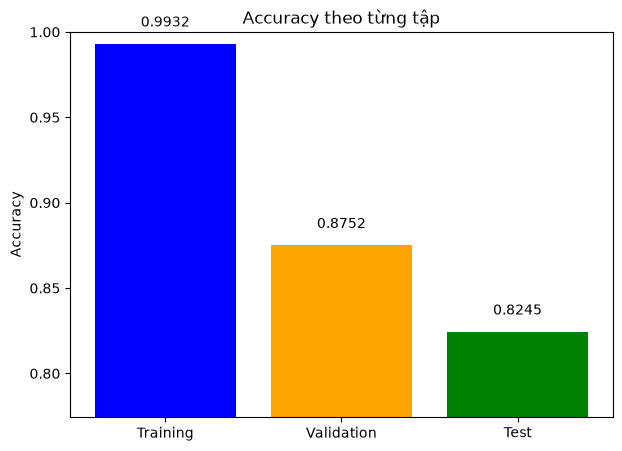

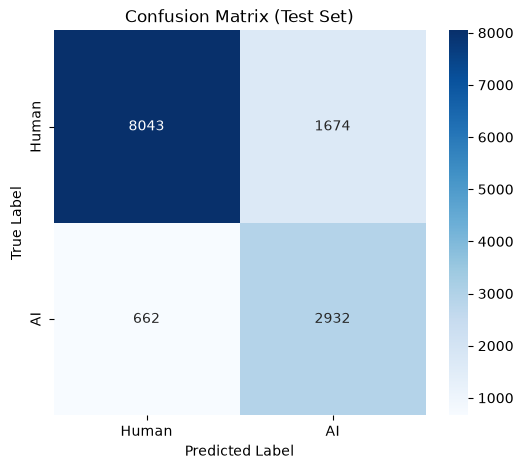

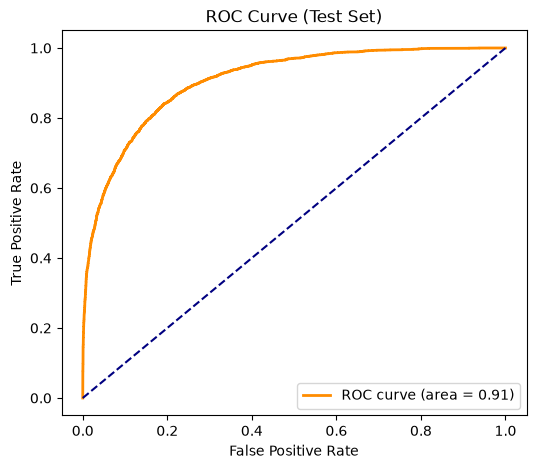

In [9]:
accuracies = {"Training": train_acc, "Validation": val_acc, "Test": test_acc}
plt.figure(figsize=(7, 5))
plt.bar(accuracies.keys(), accuracies.values(), color=["blue", "orange", "green"])
plt.ylabel("Accuracy"); plt.title("Accuracy theo từng tập")
plt.ylim([min(accuracies.values()) - 0.05, 1.0])
for i, value in enumerate(accuracies.values()):
    plt.text(i, value + 0.01, f"{value:.4f}", ha="center")
plt.show()

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Human", "AI"], yticklabels=["Human", "AI"])
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title("Confusion Matrix (Test Set)")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_test_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (Test Set)")
plt.legend(loc="lower right"); plt.show()